In [1]:
# Importar las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# URL del archivo en el bucket público de AWS
url = "https://hybridge-education-machine-learning-datasets.s3.us-east-1.amazonaws.com/Fraud.csv"
df = pd.read_csv(url)

In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
len(df)

6362620

# ¡¡¡6,362,620 OBSERVACIONES!!!

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [6]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [7]:
df['isFraud'].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [8]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Paso 2: Preprocesamiento (normalización de características)
En el preprocesamiento debemos preparar los datos para que el modelo matemático pueda procesarlos correctamente:

1. Eliminar identificadores únicos: Columnas como nameOrig y nameDest no aportan patrones de valor generalizables y tienen demasiada cardinalidad.

2. Codificación categórica (One-Hot Encoding): La columna type (tipo de transacción como CASH-IN, TRANSFER, etc.) es texto, por lo que debemos convertirla a variables numéricas binarias con pd.get_dummies.

3. División de datos: Separamos las características independientes ($X$) de la etiqueta objetivo ($y$), y dividimos en conjuntos de entrenamiento y prueba (train_test_split).

4. Normalización (StandardScaler): Escalamos las variables numéricas para que tengan media 0 y desviación estándar 1, lo cual acelera la convergencia de la regresión logística.

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Eliminación de columnas no relevantes o identificadores directos
df_processed = df.drop(columns=['nameOrig', 'nameDest', 'isFlaggedFraud']) #drop es una función que elimina columnas o filas de un DataFrame

# 2. Conversión de variables categóricas (como 'type') a variables numéricas ficticias (One-Hot Encoding)
df_processed = pd.get_dummies(df_processed, columns=['type'], drop_first=True) #get_dummies convierte variables categóricas en variables numéricas ficticias (dummy variables). drop_first=True evita la multicolinealidad eliminando una de las categorías.

# 3. Separación de características (X) y variable objetivo (y)
X = df_processed.drop(columns=['isFraud'])
y = df_processed['isFraud']

# 4. División de los datos en conjuntos de entrenamiento (80%) y prueba (20%)
# Usamos stratify=y para conservar la proporción de fraudes en ambos conjuntos
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y) #train_test_split divide los datos en conjuntos de entrenamiento y prueba

# 5. Normalización de características numéricas con StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Paso 3: Entrenamiento del modelo
Una vez limpios y escalados los datos, instanciamos el modelo de Regresión Logística. Dado que el conjunto de datos está fuertemente desbalanceado (muchos datos legítimos y muy pocos fraudes), es fundamental activar el parámetro class_weight='balanced' para penalizar los errores en la clase minoritaria (fraude) y evitar que el modelo simplemente prediga que todo es legítimo.

In [10]:
from sklearn.linear_model import LogisticRegression

# 1. Instanciar el modelo de Regresión Logística
# class_weight='balanced' ajusta los pesos inversamente proporcionales a las frecuencias de las clases
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

# 2. Entrenar el modelo utilizando los datos de entrenamiento escalados
print("Entrenando el modelo de Regresión Logística...")
model.fit(X_train_scaled, y_train)
print("¡Entrenamiento finalizado con éxito!")

Entrenando el modelo de Regresión Logística...
¡Entrenamiento finalizado con éxito!


Paso 4: Evaluación del modelo
Como estamos trabajando con un problema altamente desbalanceado, evaluar únicamente con la exactitud (accuracy) es un error grave (un modelo tonto que prediga "no fraude" tendría más del 99% de exactitud pero serviría de nada). Por ello, utilizaremos la Matriz de Confusión, el Reporte de Clasificación (Precision, Recall, F1-score) y la Curva ROC-AUC.

--- MATRIZ DE CONFUSIÓN ---
[[1206227   64654]
 [     64    1579]]


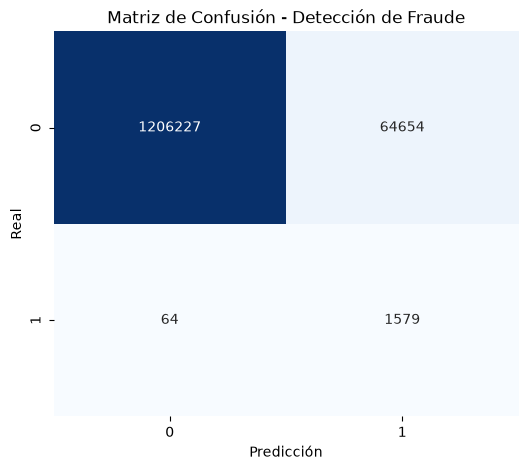


--- REPORTE DE CLASIFICACIÓN ---
              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1270881
           1       0.02      0.96      0.05      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.96      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524


ROC-AUC Score: 0.9908


In [12]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve #confusion_matrix genera la matriz de confusión, classification_report genera un informe con métricas de clasificación, roc_auc_score calcula el área bajo la curva ROC y roc_curve genera los puntos para la curva ROC
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Generar predicciones sobre el conjunto de prueba
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1] # Probabilidades para la clase positiva (fraude)

# 2. Mostrar la Matriz de Confusión
print("--- MATRIZ DE CONFUSIÓN ---")
cm = confusion_matrix(y_test, y_pred)
print(cm)

# Visualización gráfica de la matriz de confusión
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Matriz de Confusión - Detección de Fraude')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

# 3. Mostrar métricas detalladas (Precision, Recall, F1-score)
print("\n--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test, y_pred))

# 4. Calcular y mostrar el puntaje ROC-AUC
roc_auc = roc_auc_score(y_test, y_prob)
print(f"\nROC-AUC Score: {roc_auc:.4f}")